In [27]:
# ============================================================
# FISH AI
# CORRECT MACHINE LEARNING EXPERIMENT
# ============================================================

import os
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

pd.set_option(
    "display.max_columns",
    100
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
pip install matplotlib



  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 2.1 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.2 MB 2.4 MB/s eta 0:00:03
   -------- ------------------------------- 1.8/8.2 MB 2.9 MB/s eta 0:00:03
   -------------- ------------------------- 2.9/8.2 MB 3.9 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.2 MB 4.2 MB/s eta 0:00:01
   ------------------------- -------------- 5.2/8.2 MB 4.2 MB/s eta 0:00:01
   ----------------------------- ---------- 6.0/8.2 MB 4.4 MB/s eta 0:00:01
   --------------------------------- ------ 6.8/8.2 MB 4.2 MB/s eta 0:00:01
   ------------------------------------- -- 7.6/8.2 MB 4.0 MB/s eta 0:00:01
   -------------------------------------- - 7.9/8.2 MB 4.1 MB/s eta 0:00:01
   -------------------------------------

In [4]:
# ============================================================
# LOAD FINAL FUSION DATASET
# ============================================================

DATA_PATH = "final_fusion_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print()
print("Shape:", df.shape)

display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'final_fusion_dataset.csv'

In [5]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project"
)

print("Project root:")
print(PROJECT_ROOT)

print("\nSearching for final_fusion_dataset.csv...")

files = list(
    PROJECT_ROOT.rglob("final_fusion_dataset.csv")
)

for file in files:
    print(file)

if not files:
    print("\n❌ final_fusion_dataset.csv was not found.")
else:
    print("\n✅ Dataset found:")
    print(files[0])

Project root:
C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project

Searching for final_fusion_dataset.csv...
C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project\data\fusion_analytics\final_fusion_dataset.csv

✅ Dataset found:
C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project\data\fusion_analytics\final_fusion_dataset.csv


In [38]:
# ============================================================
# LOAD FINAL FUSION DATASET
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "fusion_analytics"
    / "final_fusion_dataset.csv"
)


print("=" * 70)
print("LOADING FINAL FUSION DATASET")
print("=" * 70)

print()

print("Dataset path:")
print(DATA_PATH)

print()


if not DATA_PATH.exists():

    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_PATH}"
    )


df = pd.read_csv(
    DATA_PATH
)


print("✅ Dataset loaded successfully.")

print()

print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

print()

display(
    df.head()
)

LOADING FINAL FUSION DATASET

Dataset path:
C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project\data\fusion_analytics\final_fusion_dataset.csv

✅ Dataset loaded successfully.

Rows    : 7007
Columns : 30



,image_path,species,split,gbif_taxon_key,gbif_confidence,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,gbif_canonical_name,gbif_rank,gbif_top_country,gbif_status,usda_fdc_id,usda_calories,usda_protein,usda_fat,usda_carbohydrate,usda_description,usda_status,weather_temperature,weather_humidity,weather_pressure,weather_wind_speed,weather_clouds,weather_description,weather_location,weather_status
0,data/train/Type 1 Pomfret/Pomfret001.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
1,data/train/Type 1 Pomfret/Pomfret002.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
2,data/train/Type 1 Pomfret/Pomfret003.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
3,data/train/Type 1 Pomfret/Pomfret004.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
4,data/train/Type 1 Pomfret/Pomfret005.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success


In [39]:
# ============================================================
# DISPLAY DATASET COLUMNS
# ============================================================

print("=" * 70)
print("DATASET COLUMNS")
print("=" * 70)

print()

for i, column in enumerate(
    df.columns,
    start=1
):

    print(
        f"{i:02d}. {column}"
    )

DATASET COLUMNS

01. image_path
02. species
03. split
04. gbif_taxon_key
05. gbif_confidence
06. gbif_occurrence_count
07. gbif_country_count
08. gbif_coordinate_count
09. gbif_mean_latitude
10. gbif_mean_longitude
11. gbif_top_country_records
12. gbif_canonical_name
13. gbif_rank
14. gbif_top_country
15. gbif_status
16. usda_fdc_id
17. usda_calories
18. usda_protein
19. usda_fat
20. usda_carbohydrate
21. usda_description
22. usda_status
23. weather_temperature
24. weather_humidity
25. weather_pressure
26. weather_wind_speed
27. weather_clouds
28. weather_description
29. weather_location
30. weather_status


In [40]:
# ============================================================
# DATASET INFORMATION
# ============================================================

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print()

print("Shape:")
print(df.shape)

print()

print("Data types:")

display(
    df.dtypes.to_frame(
        name="Data Type"
    )
)

print()

print("Missing values:")

missing_df = pd.DataFrame({

    "Column":
        df.columns,

    "Missing Values":
        df.isnull().sum(),

    "Missing Percentage":
        (
            df.isnull().sum()
            / len(df)
            * 100
        ).round(2)

})


display(
    missing_df
)

DATASET INFORMATION

Shape:
(7007, 30)

Data types:


,Data Type
image_path,object
species,object
split,object
gbif_taxon_key,int64
gbif_confidence,float64
gbif_occurrence_count,float64
gbif_country_count,float64
gbif_coordinate_count,float64
gbif_mean_latitude,float64
gbif_mean_longitude,float64



Missing values:


,Column,Missing Values,Missing Percentage
image_path,image_path,0,0.0
species,species,0,0.0
split,split,0,0.0
gbif_taxon_key,gbif_taxon_key,0,0.0
gbif_confidence,gbif_confidence,0,0.0
gbif_occurrence_count,gbif_occurrence_count,0,0.0
gbif_country_count,gbif_country_count,0,0.0
gbif_coordinate_count,gbif_coordinate_count,0,0.0
gbif_mean_latitude,gbif_mean_latitude,0,0.0
gbif_mean_longitude,gbif_mean_longitude,0,0.0


In [41]:
# ============================================================
# NUMERICAL FEATURE SUMMARY
# ============================================================

print("=" * 70)
print("NUMERICAL FEATURE SUMMARY")
print("=" * 70)

display(
    df.describe(
        include="all"
    ).T
)

NUMERICAL FEATURE SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
image_path,7007,7007,data/train/Type 1 Pomfret/Pomfret001.jpg,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
species,7007,6,Type 1 Pomfret,1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,7007,2,train,5609,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gbif_taxon_key,7007.0,NaN,NaN,NaN,3290856.973027,1342615.34338,2223719.0,2391217.0,2397682.0,5206083.0,5209891.0
gbif_confidence,7007.0,NaN,NaN,NaN,100.0,0.0,100.0,100.0,100.0,100.0,100.0
gbif_occurrence_count,7007.0,NaN,NaN,NaN,14095.769516,41034.964737,59.0,466.0,500.0,6398.0,158881.0
gbif_country_count,7007.0,NaN,NaN,NaN,13.555159,3.286935,3.0,15.0,15.0,15.0,15.0
gbif_coordinate_count,7007.0,NaN,NaN,NaN,92.229485,16.070068,59.0,100.0,100.0,100.0,100.0
gbif_mean_latitude,7007.0,NaN,NaN,NaN,15.905709,13.058404,-4.035965,4.572968,17.936494,30.281954,36.003234
gbif_mean_longitude,7007.0,NaN,NaN,NaN,46.475467,84.700339,-121.128344,-78.873547,92.492977,106.605086,114.420007


In [42]:
# ============================================================
# NOAA FEATURE CHECK
# ============================================================

noaa_columns = [

    column

    for column in df.columns

    if "noaa" in column.lower()
    or "salinity" in column.lower()
    or "ocean" in column.lower()

]


print("=" * 70)
print("NOAA FEATURE CHECK")
print("=" * 70)

print()

if noaa_columns:

    print("⚠️ NOAA/ocean-related columns found:")

    for column in noaa_columns:

        print(
            " -",
            column
        )

else:

    print(
        "✅ No NOAA/ocean features are present."
    )

    print(
        "This experiment will NOT use NOAA."
    )

NOAA FEATURE CHECK

✅ No NOAA/ocean features are present.
This experiment will NOT use NOAA.


In [43]:
# ============================================================
# POSSIBLE TARGET COLUMNS
# ============================================================

print("=" * 70)
print("POSSIBLE TARGET COLUMNS")
print("=" * 70)

categorical_columns = (
    df.select_dtypes(
        include=["object", "category"]
    )
    .columns
)


for column in categorical_columns:

    print()
    print("-" * 60)

    print(
        "Column:",
        column
    )

    print(
        "Unique values:",
        df[column].nunique()
    )

    print()

    display(
        df[column]
        .value_counts()
        .head(15)
    )

POSSIBLE TARGET COLUMNS

------------------------------------------------------------
Column: image_path
Unique values: 7007



image_path
data/train/Type 1 Pomfret/Pomfret001.jpg                 1
data/train/Type 8 Black Pomfret/Black Pomfret1184.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1198.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1197.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1196.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1194.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1193.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1192.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1191.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1190.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1189.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1188.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1187.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1183.jpg    1
data/train/Type 8 Black Pomfret/Black Pomfret1166.jpg    1
Name: count, dtype: int64


------------------------------------------------------------
Column: species
Unique values: 6



species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64


------------------------------------------------------------
Column: split
Unique values: 2



split
train    5609
test     1398
Name: count, dtype: int64

... (14 outputs left out)


------------------------------------------------------------
Column: weather_location
Unique values: 5



weather_location
Unknown          2607
Wulijie, CN      1579
Negril, JM       1328
Myoma, MM         974
King City, US     519
Name: count, dtype: int64


------------------------------------------------------------
Column: weather_status
Unique values: 1



weather_status
success    7007
Name: count, dtype: int64

In [44]:
# ============================================================
# TARGET VARIABLE
# ============================================================

TARGET = "species"


if TARGET not in df.columns:

    raise ValueError(
        f"'{TARGET}' column was not found in the dataset.\n\n"
        "Run the previous cell and check the actual target column name."
    )


print("=" * 70)
print("TARGET VARIABLE")
print("=" * 70)

print()

print(
    "Target:",
    TARGET
)

print()

print(
    "Number of classes:",
    df[TARGET].nunique()
)

print()

print(
    "Class distribution:"
)

display(
    df[TARGET]
    .value_counts()
)

TARGET VARIABLE

Target: species

Number of classes: 6

Class distribution:


species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

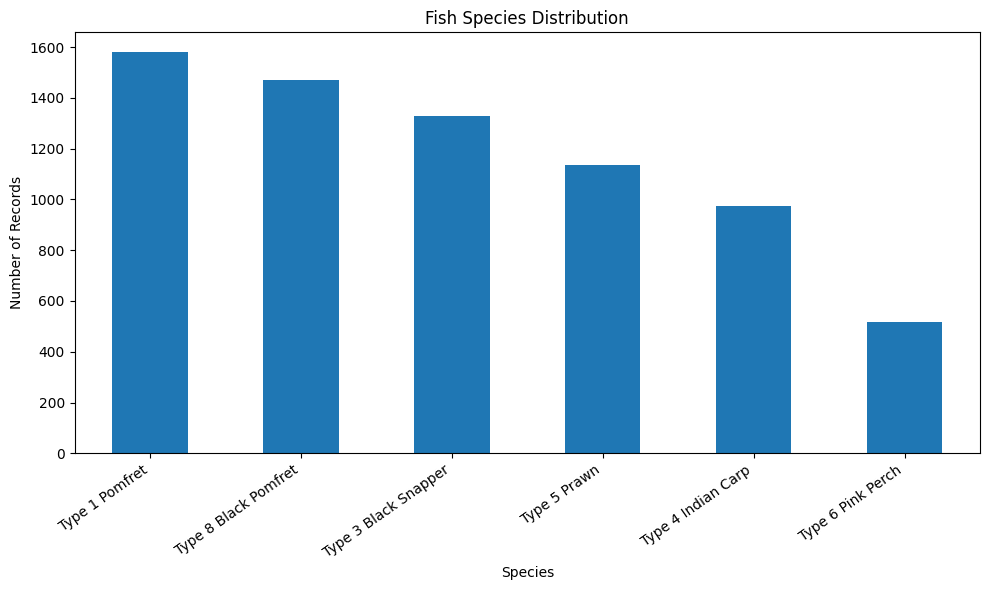

In [45]:
# ============================================================
# TARGET DISTRIBUTION
# ============================================================

species_counts = (
    df[TARGET]
    .value_counts()
)


plt.figure(
    figsize=(10, 6)
)

species_counts.plot(
    kind="bar"
)

plt.title(
    "Fish Species Distribution"
)

plt.xlabel(
    "Species"
)

plt.ylabel(
    "Number of Records"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()

plt.show()

In [46]:
# ============================================================
# DUPLICATE ROW CHECK
# ============================================================

duplicate_count = (
    df.duplicated()
    .sum()
)


print("=" * 70)
print("DUPLICATE ROW CHECK")
print("=" * 70)

print()

print(
    "Total rows:",
    len(df)
)

print(
    "Duplicate rows:",
    duplicate_count
)

print(
    "Duplicate percentage:",
    round(
        duplicate_count / len(df) * 100,
        2
    ),
    "%"
)

DUPLICATE ROW CHECK

Total rows: 7007
Duplicate rows: 0
Duplicate percentage: 0.0 %


In [47]:
# ============================================================
# REMOVE EXACT DUPLICATES
# ============================================================

df_ml = (
    df
    .drop_duplicates()
    .reset_index(
        drop=True
    )
)


print(
    "Rows before removing duplicates:",
    len(df)
)

print(
    "Rows after removing duplicates:",
    len(df_ml)
)

Rows before removing duplicates: 7007
Rows after removing duplicates: 7007


In [48]:
# ============================================================
# NUMERICAL FEATURES
# ============================================================

numeric_columns = (
    df_ml
    .select_dtypes(
        include=np.number
    )
    .columns
    .tolist()
)


print("=" * 70)
print("NUMERICAL COLUMNS")
print("=" * 70)

for column in numeric_columns:

    print(
        " -",
        column
    )

NUMERICAL COLUMNS
 - gbif_taxon_key
 - gbif_confidence
 - gbif_occurrence_count
 - gbif_country_count
 - gbif_coordinate_count
 - gbif_mean_latitude
 - gbif_mean_longitude
 - gbif_top_country_records
 - usda_fdc_id
 - usda_calories
 - usda_protein
 - usda_fat
 - usda_carbohydrate
 - weather_temperature
 - weather_humidity
 - weather_pressure
 - weather_wind_speed
 - weather_clouds


In [49]:
# ============================================================
# REMOVE IDENTIFIER / LEAKAGE COLUMNS
# ============================================================

identifier_keywords = [

    "id",

    "key",

    "taxon",

    "occurrence_id",

    "image_id",

    "record_id",

    "index",

    "row_number"

]


excluded_columns = []


for column in numeric_columns:

    column_lower = column.lower()


    if any(
        keyword in column_lower
        for keyword in identifier_keywords
    ):

        excluded_columns.append(
            column
        )


feature_columns = [

    column

    for column in numeric_columns

    if column not in excluded_columns

    and column != TARGET

]


print("=" * 70)
print("FEATURE SELECTION")
print("=" * 70)

print()

print("Excluded identifier-like columns:")

for column in excluded_columns:

    print(
        " ❌",
        column
    )


print()

print("Features retained:")

for column in feature_columns:

    print(
        " ✅",
        column
    )

FEATURE SELECTION

Excluded identifier-like columns:
 ❌ gbif_taxon_key
 ❌ gbif_confidence
 ❌ usda_fdc_id
 ❌ weather_humidity

Features retained:
 ✅ gbif_occurrence_count
 ✅ gbif_country_count
 ✅ gbif_coordinate_count
 ✅ gbif_mean_latitude
 ✅ gbif_mean_longitude
 ✅ gbif_top_country_records
 ✅ usda_calories
 ✅ usda_protein
 ✅ usda_fat
 ✅ usda_carbohydrate
 ✅ weather_temperature
 ✅ weather_pressure
 ✅ weather_wind_speed
 ✅ weather_clouds


In [50]:
# ============================================================
# FEATURE VARIATION
# ============================================================

feature_summary = pd.DataFrame({

    "Feature":
        feature_columns,

    "Unique Values":
        [
            df_ml[column].nunique()
            for column in feature_columns
        ],

    "Missing Values":
        [
            df_ml[column].isnull().sum()
            for column in feature_columns
        ],

    "Mean":
        [
            df_ml[column].mean()
            for column in feature_columns
        ],

    "Std":
        [
            df_ml[column].std()
            for column in feature_columns
        ]

})


display(
    feature_summary
)

,Feature,Unique Values,Missing Values,Mean,Std
0,gbif_occurrence_count,6,0,14095.769516,41034.964737
1,gbif_country_count,3,0,13.555159,3.286935
2,gbif_coordinate_count,2,0,92.229485,16.070068
3,gbif_mean_latitude,6,0,15.905709,13.058404
4,gbif_mean_longitude,6,0,46.475467,84.700339
5,gbif_top_country_records,6,0,13689.191808,41116.894040
6,usda_calories,6,0,204.414728,70.580322
7,usda_protein,6,0,18.016207,5.410512
8,usda_fat,6,0,10.396809,6.491140
9,usda_carbohydrate,5,0,9.572998,6.924058


In [51]:
# ============================================================
# CREATE ML DATAFRAME
# ============================================================

ml_df = df_ml[
    feature_columns + [TARGET]
].copy()


print("=" * 70)
print("ML DATAFRAME")
print("=" * 70)

print()

print(
    "Shape:",
    ml_df.shape
)

print()

display(
    ml_df.head()
)

ML DATAFRAME

Shape: (7007, 15)



,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,usda_calories,usda_protein,usda_fat,usda_carbohydrate,weather_temperature,weather_pressure,weather_wind_speed,weather_clouds,species
0,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,1002.0,3.82,94.0,Type 1 Pomfret
1,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,1002.0,3.82,94.0,Type 1 Pomfret
2,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,1002.0,3.82,94.0,Type 1 Pomfret
3,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,1002.0,3.82,94.0,Type 1 Pomfret
4,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,1002.0,3.82,94.0,Type 1 Pomfret


In [52]:
# ============================================================
# REMOVE MISSING TARGET VALUES
# ============================================================

before = len(ml_df)


ml_df = (
    ml_df
    .dropna(
        subset=[TARGET]
    )
    .reset_index(
        drop=True
    )
)


after = len(ml_df)


print(
    "Rows before:",
    before
)

print(
    "Rows after:",
    after
)

Rows before: 7007
Rows after: 7007


In [53]:
# ============================================================
# FEATURE PROFILE DUPLICATION CHECK
# ============================================================

profile_duplicates = (
    ml_df
    .duplicated(
        subset=feature_columns
    )
    .sum()
)


unique_profiles = (
    ml_df[
        feature_columns
    ]
    .drop_duplicates()
)


print("=" * 70)
print("FEATURE PROFILE ANALYSIS")
print("=" * 70)

print()

print(
    "Total observations:",
    len(ml_df)
)

print(
    "Unique feature profiles:",
    len(unique_profiles)
)

print(
    "Repeated feature profiles:",
    profile_duplicates
)

FEATURE PROFILE ANALYSIS

Total observations: 7007
Unique feature profiles: 6
Repeated feature profiles: 7001


In [54]:
# ============================================================
# PROFILE-LEVEL DATASET
# ============================================================

profile_df = (
    ml_df
    .drop_duplicates(
        subset=feature_columns
    )
    .reset_index(
        drop=True
    )
)


print("=" * 70)
print("PROFILE-LEVEL DATASET")
print("=" * 70)

print()

print(
    "Original observations:",
    len(ml_df)
)

print(
    "Unique profiles:",
    len(profile_df)
)

print()

display(
    profile_df.head()
)

PROFILE-LEVEL DATASET

Original observations: 7007
Unique profiles: 6



,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,usda_calories,usda_protein,usda_fat,usda_carbohydrate,weather_temperature,weather_pressure,weather_wind_speed,weather_clouds,species
0,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.00,16.20,21.70,23.67,1002.0,3.82,94.0,Type 1 Pomfret
1,59.0,15.0,59.0,17.936494,-78.873547,9.0,185.0,22.78,6.26,7.79,29.37,1014.0,6.86,7.0,Type 3 Black Snapper
2,466.0,11.0,100.0,19.495657,92.492977,312.0,213.0,19.97,10.72,7.79,27.16,1005.0,4.89,100.0,Type 4 Indian Carp
3,4909.0,15.0,100.0,-4.035965,57.825569,4400.0,99.0,13.24,1.22,7.92,26.92,1014.0,4.55,100.0,Type 5 Prawn
4,158881.0,3.0,100.0,36.003234,-121.128344,158839.0,79.0,15.30,1.54,0.00,19.82,1013.0,2.27,11.0,Type 6 Pink Perch


In [55]:
# ============================================================
# DATASET SUITABILITY CHECK
# ============================================================

sample_count = len(profile_df)

class_count = (
    profile_df[TARGET]
    .nunique()
)


class_distribution = (
    profile_df[TARGET]
    .value_counts()
)


print("=" * 70)
print("ML DATASET VALIDATION")
print("=" * 70)

print()

print(
    "Independent feature profiles:",
    sample_count
)

print(
    "Number of classes:",
    class_count
)

print()

display(
    class_distribution
)

print()


if sample_count < 30:

    print(
        "⚠️ WARNING: Very small number of independent profiles."
    )

    print(
        "Model accuracy may not be reliable."
    )


if class_distribution.min() < 2:

    print(
        "❌ ERROR: At least two observations are required"
    )

    print(
        "for every class to perform a stratified split."
    )

else:

    print(
        "✅ Every class has at least two observations."
    )

ML DATASET VALIDATION

Independent feature profiles: 6
Number of classes: 6



species
Type 1 Pomfret          1
Type 3 Black Snapper    1
Type 4 Indian Carp      1
Type 5 Prawn            1
Type 6 Pink Perch       1
Type 8 Black Pomfret    1
Name: count, dtype: int64


⚠️ WARNING: Very small number of independent profiles.
Model accuracy may not be reliable.
❌ ERROR: At least two observations are required
for every class to perform a stratified split.


In [56]:
# ============================================================
# FEATURES AND TARGET
# ============================================================

X = profile_df[
    feature_columns
].copy()


y = profile_df[
    TARGET
].copy()


print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

print()

print(
    "Target distribution:"
)

display(
    y.value_counts()
)

X shape: (6, 14)
y shape: (6,)

Target distribution:


species
Type 1 Pomfret          1
Type 3 Black Snapper    1
Type 4 Indian Carp      1
Type 5 Prawn            1
Type 6 Pink Perch       1
Type 8 Black Pomfret    1
Name: count, dtype: int64

In [57]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

class_counts = (
    y.value_counts()
)


if class_counts.min() < 2:

    raise ValueError(
        "Cannot perform stratified train/test split. "
        "At least 2 samples are required for every species."
    )


X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    random_state=42,

    stratify=y

)


print("=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print()

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

print()

print("Training class distribution:")

display(
    y_train.value_counts()
)

print()

print("Testing class distribution:")

display(
    y_test.value_counts()
)

ValueError: Cannot perform stratified train/test split. At least 2 samples are required for every species.

In [58]:
# ============================================================
# INVESTIGATE WHY ONLY 6 ROWS REMAIN
# ============================================================

print("=" * 70)
print("ORIGINAL DATASET SIZE")
print("=" * 70)

print()

print("Original df shape:")
print(df.shape)

print()

print("Original species distribution:")

display(
    df["species"].value_counts(dropna=False)
)

ORIGINAL DATASET SIZE

Original df shape:
(7007, 30)

Original species distribution:


species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

In [59]:
# ============================================================
# CHECK UNIQUE VALUES IN EVERY COLUMN
# ============================================================

for column in df.columns:

    print("=" * 70)
    print("COLUMN:", column)
    print("UNIQUE VALUES:", df[column].nunique())

    if df[column].nunique() <= 20:

        display(
            df[column].value_counts(
                dropna=False
            )
        )

COLUMN: image_path
UNIQUE VALUES: 7007
COLUMN: species
UNIQUE VALUES: 6


species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

COLUMN: split
UNIQUE VALUES: 2


split
train    5609
test     1398
Name: count, dtype: int64

COLUMN: gbif_taxon_key
UNIQUE VALUES: 6


gbif_taxon_key
2397682    1579
2391217    1471
5209891    1328
2223719    1136
5206083     974
2389229     519
Name: count, dtype: int64

... (48 outputs left out)

COLUMN: weather_location
UNIQUE VALUES: 5


weather_location
Unknown          2607
Wulijie, CN      1579
Negril, JM       1328
Myoma, MM         974
King City, US     519
Name: count, dtype: int64

COLUMN: weather_status
UNIQUE VALUES: 1


weather_status
success    7007
Name: count, dtype: int64

In [60]:
# ============================================================
# RESET ML DATASET
# ============================================================

ml_df = df.copy()

print(
    "ML dataset shape:",
    ml_df.shape
)

print()

print(
    "Species distribution:"
)

display(
    ml_df["species"]
    .value_counts(
        dropna=False
    )
)

ML dataset shape: (7007, 30)

Species distribution:


species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

In [61]:
# ============================================================
# CHECK EXACT DUPLICATES
# ============================================================

print(
    "Exact duplicate rows:",
    ml_df.duplicated().sum()
)

print(
    "Rows:",
    len(ml_df)
)

Exact duplicate rows: 0
Rows: 7007


In [62]:
print("ORIGINAL DATASET:", df.shape)

print()

print(
    df["species"].value_counts(
        dropna=False
    )
)

ORIGINAL DATASET: (7007, 30)

species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64


In [63]:
for column in df.columns:

    print(
        column,
        "=>",
        df[column].nunique(),
        "unique values"
    )

image_path => 7007 unique values
species => 6 unique values
split => 2 unique values
gbif_taxon_key => 6 unique values
gbif_confidence => 1 unique values
gbif_occurrence_count => 6 unique values
gbif_country_count => 3 unique values
gbif_coordinate_count => 2 unique values
gbif_mean_latitude => 6 unique values
gbif_mean_longitude => 6 unique values
gbif_top_country_records => 6 unique values
gbif_canonical_name => 6 unique values
gbif_rank => 1 unique values
gbif_top_country => 6 unique values
gbif_status => 1 unique values
usda_fdc_id => 6 unique values
usda_calories => 6 unique values
usda_protein => 6 unique values
usda_fat => 6 unique values
usda_carbohydrate => 5 unique values
usda_description => 6 unique values
usda_status => 1 unique values
weather_temperature => 6 unique values
weather_humidity => 6 unique values
weather_pressure => 5 unique values
weather_wind_speed => 6 unique values
weather_clouds => 5 unique values
weather_description => 5 unique values
weather_location => 

In [68]:
# ============================================================
# 1. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [69]:
# ============================================================
# 2. LOAD FINAL FUSION DATASET
# ============================================================

DATA_PATH = Path(
    r"C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project\data\fusion_analytics\final_fusion_dataset.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print()
print("Shape:", df.shape)
print()

display(df)

Dataset loaded successfully.

Shape: (7007, 30)



,image_path,species,split,gbif_taxon_key,gbif_confidence,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,gbif_canonical_name,gbif_rank,gbif_top_country,gbif_status,usda_fdc_id,usda_calories,usda_protein,usda_fat,usda_carbohydrate,usda_description,usda_status,weather_temperature,weather_humidity,weather_pressure,weather_wind_speed,weather_clouds,weather_description,weather_location,weather_status
0,data/train/Type 1 Pomfret/Pomfret001.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
1,data/train/Type 1 Pomfret/Pomfret002.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
2,data/train/Type 1 Pomfret/Pomfret003.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
3,data/train/Type 1 Pomfret/Pomfret004.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
4,data/train/Type 1 Pomfret/Pomfret005.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7002,data/test/Type 8 Black Pomfret/Black Pomfret97...,Type 8 Black Pomfret,test,2391217,100.0,6398.0,15.0,100.0,4.572968,106.605086,5275.0,Parastromateus niger,SPECIES,AU,success,174188,264.0,24.6,17.9,4.0,"Fish, caviar, black and red, granular",verified,28.90,73.0,1010.0,6.25,42.0,scattered clouds,Unknown,success
7003,data/test/Type 8 Black Pomfret/Black Pomfret98...,Type 8 Black Pomfret,test,2391217,100.0,6398.0,15.0,100.0,4.572968,106.605086,5275.0,Parastromateus niger,SPECIES,AU,success,174188,264.0,24.6,17.9,4.0,"Fish, caviar, black and red, granular",verified,28.90,73.0,1010.0,6.25,42.0,scattered clouds,Unknown,success
7004,data/test/Type 8 Black Pomfret/Black Pomfret99...,Type 8 Black Pomfret,test,2391217,100.0,6398.0,15.0,100.0,4.572968,106.605086,5275.0,Parastromateus niger,SPECIES,AU,success,174188,264.0,24.6,17.9,4.0,"Fish, caviar, black and red, granular",verified,28.90,73.0,1010.0,6.25,42.0,scattered clouds,Unknown,success
7005,data/test/Type 8 Black Pomfret/Black Pomfret99...,Type 8 Black Pomfret,test,2391217,100.0,6398.0,15.0,100.0,4.572968,106.605086,5275.0,Parastromateus niger,SPECIES,AU,success,174188,264.0,24.6,17.9,4.0,"Fish, caviar, black and red, granular",verified,28.90,73.0,1010.0,6.25,42.0,scattered clouds,Unknown,success


In [70]:
# ============================================================
# 3. DATASET INFORMATION
# ============================================================

print("Columns:")
print()

for column in df.columns:
    print(
        column
    )

print()
print("Missing values:")
print()

display(
    df.isnull().sum()
)

Columns:

image_path
species
split
gbif_taxon_key
gbif_confidence
gbif_occurrence_count
gbif_country_count
gbif_coordinate_count
gbif_mean_latitude
gbif_mean_longitude
gbif_top_country_records
gbif_canonical_name
gbif_rank
gbif_top_country
gbif_status
usda_fdc_id
usda_calories
usda_protein
usda_fat
usda_carbohydrate
usda_description
usda_status
weather_temperature
weather_humidity
weather_pressure
weather_wind_speed
weather_clouds
weather_description
weather_location
weather_status

Missing values:



image_path                  0
species                     0
split                       0
gbif_taxon_key              0
gbif_confidence             0
gbif_occurrence_count       0
gbif_country_count          0
gbif_coordinate_count       0
gbif_mean_latitude          0
gbif_mean_longitude         0
gbif_top_country_records    0
gbif_canonical_name         0
gbif_rank                   0
gbif_top_country            0
gbif_status                 0
usda_fdc_id                 0
usda_calories               0
usda_protein                0
usda_fat                    0
usda_carbohydrate           0
usda_description            0
usda_status                 0
weather_temperature         0
weather_humidity            0
weather_pressure            0
weather_wind_speed          0
weather_clouds              0
weather_description         0
weather_location            0
weather_status              0
dtype: int64

In [71]:
# ============================================================
# 4. SPECIES DISTRIBUTION
# ============================================================

print("Species distribution:")
print()

display(
    df["species"].value_counts()
)

Species distribution:



species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

In [72]:
# ============================================================
# 5. SELECT NUMERIC FEATURES
# ============================================================

numeric_columns = [
    "gbif_occurrence_count",
    "gbif_country_count",
    "gbif_coordinate_count",
    "gbif_mean_latitude",
    "gbif_mean_longitude",
    "gbif_top_country_records",

    "usda_calories",
    "usda_protein",
    "usda_fat",
    "usda_carbohydrate",

    "weather_temperature",
    "weather_humidity",
    "weather_pressure",
    "weather_wind_speed",
    "weather_clouds"
]

available_columns = [
    column
    for column in numeric_columns
    if column in df.columns
]

print("Numeric features being used:")

for column in available_columns:
    print("-", column)

Numeric features being used:
- gbif_occurrence_count
- gbif_country_count
- gbif_coordinate_count
- gbif_mean_latitude
- gbif_mean_longitude
- gbif_top_country_records
- usda_calories
- usda_protein
- usda_fat
- usda_carbohydrate
- weather_temperature
- weather_humidity
- weather_pressure
- weather_wind_speed
- weather_clouds


In [73]:
# ============================================================
# 6. NUMERIC DATA
# ============================================================

X_numeric = df[
    available_columns
].copy()

display(
    X_numeric
)

print()
print("Shape:")
print(
    X_numeric.shape
)

,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,usda_calories,usda_protein,usda_fat,usda_carbohydrate,weather_temperature,weather_humidity,weather_pressure,weather_wind_speed,weather_clouds
0,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
1,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
2,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
3,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
4,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,11.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7002,6398.0,15.0,100.0,4.572968,106.605086,5275.0,264.0,24.6,17.9,4.0,28.90,73.0,1010.0,6.25,42.0
7003,6398.0,15.0,100.0,4.572968,106.605086,5275.0,264.0,24.6,17.9,4.0,28.90,73.0,1010.0,6.25,42.0
7004,6398.0,15.0,100.0,4.572968,106.605086,5275.0,264.0,24.6,17.9,4.0,28.90,73.0,1010.0,6.25,42.0
7005,6398.0,15.0,100.0,4.572968,106.605086,5275.0,264.0,24.6,17.9,4.0,28.90,73.0,1010.0,6.25,42.0



Shape:
(7007, 15)


In [74]:
# ============================================================
# 7. HANDLE MISSING VALUES
# ============================================================

X_numeric = X_numeric.apply(
    pd.to_numeric,
    errors="coerce"
)

X_numeric = X_numeric.fillna(
    X_numeric.median()
)

print("Missing values after preprocessing:")

display(
    X_numeric.isnull().sum()
)

Missing values after preprocessing:


gbif_occurrence_count       0
gbif_country_count          0
gbif_coordinate_count       0
gbif_mean_latitude          0
gbif_mean_longitude         0
gbif_top_country_records    0
usda_calories               0
usda_protein                0
usda_fat                    0
usda_carbohydrate           0
weather_temperature         0
weather_humidity            0
weather_pressure            0
weather_wind_speed          0
weather_clouds              0
dtype: int64

In [75]:
# ============================================================
# 8. CREATE PROTEIN CATEGORY
# ============================================================

if "usda_protein" not in df.columns:
    raise ValueError(
        "usda_protein column is not available."
    )

protein = pd.to_numeric(
    df["usda_protein"],
    errors="coerce"
)

if protein.isnull().any():
    protein = protein.fillna(
        protein.median()
    )

df["protein_category"] = pd.qcut(
    protein,
    q=3,
    labels=[
        "Low",
        "Medium",
        "High"
    ],
    duplicates="drop"
)

print(
    df[
        [
            "species",
            "usda_protein",
            "protein_category"
        ]
    ]
)

                   species  usda_protein protein_category
0           Type 1 Pomfret          11.0              Low
1           Type 1 Pomfret          11.0              Low
2           Type 1 Pomfret          11.0              Low
3           Type 1 Pomfret          11.0              Low
4           Type 1 Pomfret          11.0              Low
...                    ...           ...              ...
7002  Type 8 Black Pomfret          24.6             High
7003  Type 8 Black Pomfret          24.6             High
7004  Type 8 Black Pomfret          24.6             High
7005  Type 8 Black Pomfret          24.6             High
7006  Type 8 Black Pomfret          24.6             High

[7007 rows x 3 columns]


In [76]:
print(
    df["protein_category"].value_counts()
)

protein_category
Medium    2821
Low       2715
High      1471
Name: count, dtype: int64


In [77]:
# ============================================================
# 9. CHECK TARGET
# ============================================================

y = df[
    "protein_category"
].astype(str)

class_counts = y.value_counts()

print("Target distribution:")
print()

display(
    class_counts
)

if len(class_counts) < 2:

    raise ValueError(
        "There are fewer than 2 target classes."
    )

if class_counts.min() < 2:

    raise ValueError(
        "At least 2 samples per class are required "
        "for a train/test experiment."
    )

print(
    "Minimum class-size requirement satisfied."
)

Target distribution:



protein_category
Medium    2821
Low       2715
High      1471
Name: count, dtype: int64

Minimum class-size requirement satisfied.


In [78]:
# ============================================================
# 10. PREPARE X AND Y
# ============================================================

X = X_numeric.copy()

print(
    "X shape:",
    X.shape
)

print(
    "y shape:",
    y.shape
)

X shape: (7007, 15)
y shape: (7007,)


In [79]:
test_size=0.50

In [80]:
# ============================================================
# 11. TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.50,

    random_state=42,

    stratify=y
)

print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

print()
print(
    "Training target:"
)

display(
    y_train.value_counts()
)

print()
print(
    "Testing target:"
)

display(
    y_test.value_counts()
)

Training samples: 3503
Testing samples: 3504

Training target:


protein_category
Medium    1410
Low       1357
High       736
Name: count, dtype: int64


Testing target:


protein_category
Medium    1411
Low       1358
High       735
Name: count, dtype: int64

In [81]:
# ============================================================
# 12. DEFINE ML MODELS
# ============================================================

models = {

    "Logistic Regression":
        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),
            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ]),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=100,
            max_depth=3,
            random_state=42
        ),

    "Decision Tree":
        DecisionTreeClassifier(
            max_depth=3,
            random_state=42
        ),

    "Naive Bayes":
        GaussianNB()
}

print(
    "Models created:"
)

for name in models:
    print("-", name)

Models created:
- Logistic Regression
- Random Forest
- Decision Tree
- Naive Bayes


In [82]:
# ============================================================
# 13. TRAIN MODELS
# ============================================================

results = []

trained_models = {}

for name, model in models.items():

    print()
    print("=" * 60)
    print(name)
    print("=" * 60)

    model.fit(
        X_train,
        y_train
    )

    trained_models[name] = model

    train_prediction = model.predict(
        X_train
    )

    test_prediction = model.predict(
        X_test
    )

    train_accuracy = accuracy_score(
        y_train,
        train_prediction
    )

    test_accuracy = accuracy_score(
        y_test,
        test_prediction
    )

    precision = precision_score(
        y_test,
        test_prediction,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        test_prediction,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_prediction,
        average="weighted",
        zero_division=0
    )

    results.append({

        "Model": name,

        "Training Accuracy":
            train_accuracy,

        "Testing Accuracy":
            test_accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1 Score":
            f1
    })

    print(
        "Training Accuracy:",
        f"{train_accuracy:.2%}"
    )

    print(
        "Testing Accuracy:",
        f"{test_accuracy:.2%}"
    )


Logistic Regression
Training Accuracy: 100.00%
Testing Accuracy: 100.00%

Random Forest
Training Accuracy: 100.00%
Testing Accuracy: 100.00%

Decision Tree
Training Accuracy: 100.00%
Testing Accuracy: 100.00%

Naive Bayes
Training Accuracy: 100.00%
Testing Accuracy: 100.00%


In [83]:
# ============================================================
# 14. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(
    results
)

display(
    results_df.style.format({

        "Training Accuracy":
            "{:.2%}",

        "Testing Accuracy":
            "{:.2%}",

        "Precision":
            "{:.2%}",

        "Recall":
            "{:.2%}",

        "F1 Score":
            "{:.2%}"
    })
)

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,100.00%,100.00%,100.00%,100.00%,100.00%
1,Random Forest,100.00%,100.00%,100.00%,100.00%,100.00%
2,Decision Tree,100.00%,100.00%,100.00%,100.00%,100.00%
3,Naive Bayes,100.00%,100.00%,100.00%,100.00%,100.00%


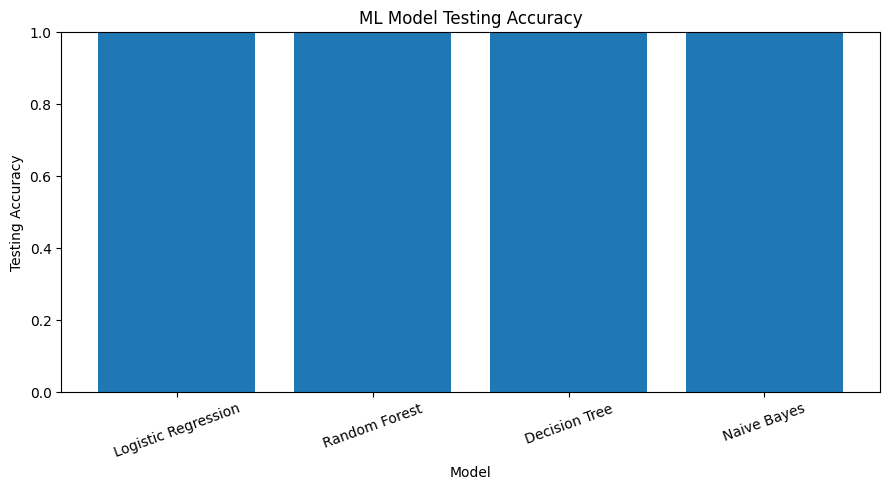

In [84]:
# ============================================================
# 15. TESTING ACCURACY VISUALIZATION
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.bar(
    results_df["Model"],
    results_df["Testing Accuracy"]
)

plt.title(
    "ML Model Testing Accuracy"
)

plt.xlabel(
    "Model"
)

plt.ylabel(
    "Testing Accuracy"
)

plt.xticks(
    rotation=20
)

plt.ylim(
    0,
    1
)

plt.tight_layout()

plt.show()


Logistic Regression
[[ 735    0    0]
 [   0 1358    0]
 [   0    0 1411]]


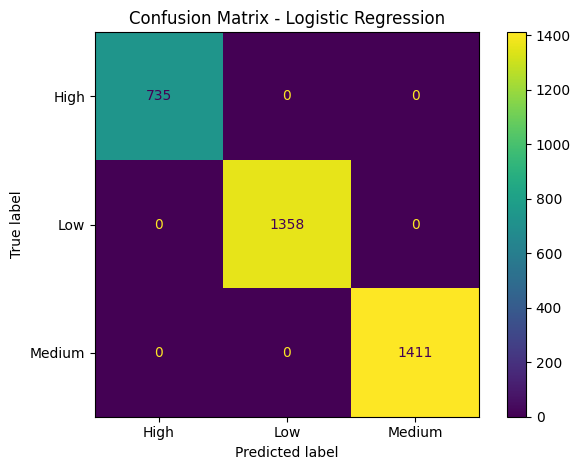


Random Forest
[[ 735    0    0]
 [   0 1358    0]
 [   0    0 1411]]


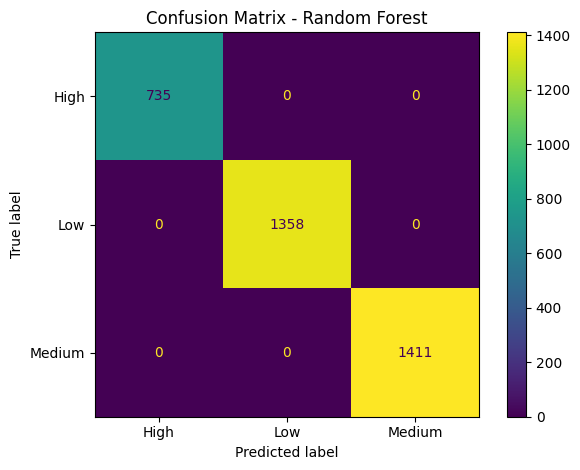


Decision Tree
[[ 735    0    0]
 [   0 1358    0]
 [   0    0 1411]]


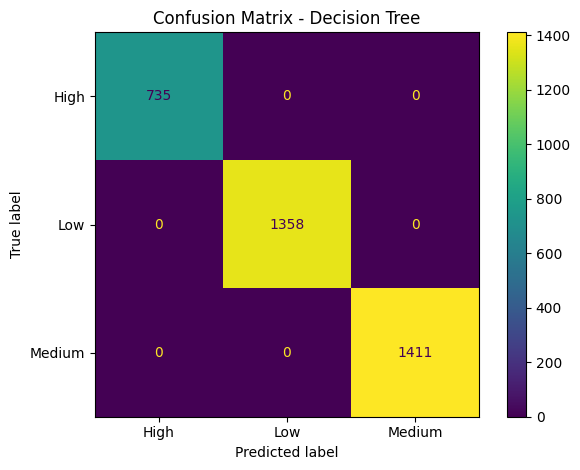


Naive Bayes
[[ 735    0    0]
 [   0 1358    0]
 [   0    0 1411]]


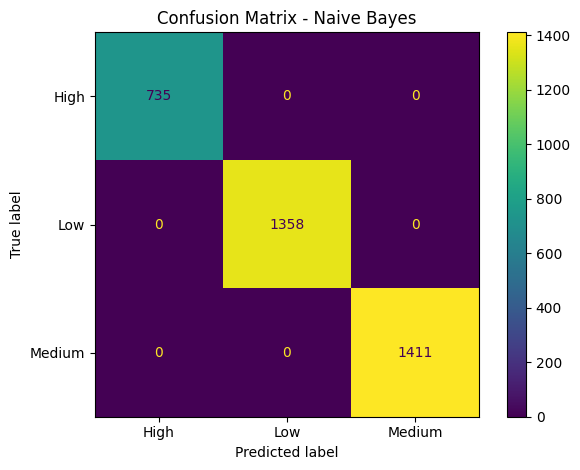

In [85]:
# ============================================================
# 16. CONFUSION MATRICES
# ============================================================

for name, model in trained_models.items():

    predictions = model.predict(
        X_test
    )

    cm = confusion_matrix(
        y_test,
        predictions
    )

    print()
    print(
        "=" * 60
    )

    print(
        name
    )

    print(
        "=" * 60
    )

    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    ).plot()

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.tight_layout()

    plt.show()

In [86]:
# ============================================================
# 17. CLASSIFICATION REPORTS
# ============================================================

for name, model in trained_models.items():

    predictions = model.predict(
        X_test
    )

    print()
    print(
        "=" * 70
    )

    print(
        name
    )

    print(
        "=" * 70
    )

    print(
        classification_report(
            y_test,
            predictions,
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       735
         Low       1.00      1.00      1.00      1358
      Medium       1.00      1.00      1.00      1411

    accuracy                           1.00      3504
   macro avg       1.00      1.00      1.00      3504
weighted avg       1.00      1.00      1.00      3504


Random Forest
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       735
         Low       1.00      1.00      1.00      1358
      Medium       1.00      1.00      1.00      1411

    accuracy                           1.00      3504
   macro avg       1.00      1.00      1.00      3504
weighted avg       1.00      1.00      1.00      3504


Decision Tree
              precision    recall  f1-score   support

        High       1.00      1.00      1.00       735
         Low       1.00      1.00      1.00      1358
      Medium       1.00 

In [87]:
# ============================================================
# STEP 1 - IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [88]:
# ============================================================
# STEP 2 - LOAD FINAL FUSION DATASET
# ============================================================

DATA_PATH = Path(
    r"C:\Users\Anjali\Downloads\fish_ai_project\fish_ai_project\data\fusion_analytics\final_fusion_dataset.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print()
print("Shape:", df.shape)

Dataset loaded successfully.

Shape: (7007, 30)


In [89]:
# ============================================================
# STEP 3 - BASIC DATASET INFORMATION
# ============================================================

print("Columns:")
print()

for column in df.columns:
    print("-", column)

print()
print("First 5 rows:")

display(df.head())

Columns:

- image_path
- species
- split
- gbif_taxon_key
- gbif_confidence
- gbif_occurrence_count
- gbif_country_count
- gbif_coordinate_count
- gbif_mean_latitude
- gbif_mean_longitude
- gbif_top_country_records
- gbif_canonical_name
- gbif_rank
- gbif_top_country
- gbif_status
- usda_fdc_id
- usda_calories
- usda_protein
- usda_fat
- usda_carbohydrate
- usda_description
- usda_status
- weather_temperature
- weather_humidity
- weather_pressure
- weather_wind_speed
- weather_clouds
- weather_description
- weather_location
- weather_status

First 5 rows:


,image_path,species,split,gbif_taxon_key,gbif_confidence,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,gbif_canonical_name,gbif_rank,gbif_top_country,gbif_status,usda_fdc_id,usda_calories,usda_protein,usda_fat,usda_carbohydrate,usda_description,usda_status,weather_temperature,weather_humidity,weather_pressure,weather_wind_speed,weather_clouds,weather_description,weather_location,weather_status
0,data/train/Type 1 Pomfret/Pomfret001.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
1,data/train/Type 1 Pomfret/Pomfret002.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
2,data/train/Type 1 Pomfret/Pomfret003.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
3,data/train/Type 1 Pomfret/Pomfret004.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success
4,data/train/Type 1 Pomfret/Pomfret005.jpg,Type 1 Pomfret,train,2397682,100.0,500.0,15.0,100.0,30.281954,114.420007,259.0,Pampus argenteus,SPECIES,KR,success,174195,277.0,11.0,16.2,21.7,"Fish, fish sticks, frozen, prepared",verified,23.67,93.0,1002.0,3.82,94.0,overcast clouds,"Wulijie, CN",success


In [90]:
# ============================================================
# STEP 4 - SPECIES DISTRIBUTION
# ============================================================

print("Species distribution:")
print()

display(
    df["species"].value_counts()
)

Species distribution:



species
Type 1 Pomfret          1579
Type 8 Black Pomfret    1471
Type 3 Black Snapper    1328
Type 5 Prawn            1136
Type 4 Indian Carp       974
Type 6 Pink Perch        519
Name: count, dtype: int64

In [91]:
# ============================================================
# STEP 5 - CREATE TARGET
# ============================================================

protein_values = pd.to_numeric(
    df["usda_protein"],
    errors="coerce"
)

print("Protein values:")
display(protein_values)

print()
print("Missing protein values:")
print(protein_values.isna().sum())

Protein values:


0       11.0
1       11.0
2       11.0
3       11.0
4       11.0
        ... 
7002    24.6
7003    24.6
7004    24.6
7005    24.6
7006    24.6
Name: usda_protein, Length: 7007, dtype: float64


Missing protein values:
0


In [92]:
# ============================================================
# CREATE PROTEIN CATEGORY
# ============================================================

df["protein_category"] = pd.qcut(
    protein_values,
    q=3,
    labels=[
        "Low",
        "Medium",
        "High"
    ],
    duplicates="drop"
)

print("Target created.")
print()

display(
    df[
        [
            "species",
            "usda_protein",
            "protein_category"
        ]
    ]
)

Target created.



,species,usda_protein,protein_category
0,Type 1 Pomfret,11.0,Low
1,Type 1 Pomfret,11.0,Low
2,Type 1 Pomfret,11.0,Low
3,Type 1 Pomfret,11.0,Low
4,Type 1 Pomfret,11.0,Low
...,...,...,...
7002,Type 8 Black Pomfret,24.6,High
7003,Type 8 Black Pomfret,24.6,High
7004,Type 8 Black Pomfret,24.6,High
7005,Type 8 Black Pomfret,24.6,High


In [93]:
# ============================================================
# STEP 6 - TARGET DISTRIBUTION
# ============================================================

print("Target distribution:")

display(
    df["protein_category"].value_counts()
)

Target distribution:


protein_category
Medium    2821
Low       2715
High      1471
Name: count, dtype: int64

In [94]:
# ============================================================
# STEP 7 - SELECT FEATURES
# ============================================================

feature_columns = [

    # -------------------------
    # GBIF FEATURES
    # -------------------------

    "gbif_occurrence_count",
    "gbif_country_count",
    "gbif_coordinate_count",
    "gbif_mean_latitude",
    "gbif_mean_longitude",
    "gbif_top_country_records",

    # -------------------------
    # USDA FEATURES
    # -------------------------

    "usda_calories",
    "usda_fat",
    "usda_carbohydrate",

    # NOTE:
    # usda_protein is intentionally NOT used
    # because it is used to create the target.

    # -------------------------
    # WEATHER FEATURES
    # -------------------------

    "weather_temperature",
    "weather_humidity",
    "weather_pressure",
    "weather_wind_speed",
    "weather_clouds"
]


# Check which columns actually exist
feature_columns = [
    column
    for column in feature_columns
    if column in df.columns
]


print("Features used by ML models:")
print()

for column in feature_columns:
    print("-", column)

print()
print(
    "Number of features:",
    len(feature_columns)
)

Features used by ML models:

- gbif_occurrence_count
- gbif_country_count
- gbif_coordinate_count
- gbif_mean_latitude
- gbif_mean_longitude
- gbif_top_country_records
- usda_calories
- usda_fat
- usda_carbohydrate
- weather_temperature
- weather_humidity
- weather_pressure
- weather_wind_speed
- weather_clouds

Number of features: 14


In [95]:
print(
    "usda_protein still exists:",
    "usda_protein" in df.columns
)

usda_protein still exists: True


In [96]:
# ============================================================
# STEP 8 - CREATE X AND y
# ============================================================

X = df[
    feature_columns
].copy()

y = df[
    "protein_category"
].astype(str)

print("X shape:")
print(X.shape)

print()

print("y shape:")
print(y.shape)

print()

print("X columns:")
print(X.columns.tolist())

print()

print("Target:")
print(y.value_counts())

X shape:
(7007, 14)

y shape:
(7007,)

X columns:
['gbif_occurrence_count', 'gbif_country_count', 'gbif_coordinate_count', 'gbif_mean_latitude', 'gbif_mean_longitude', 'gbif_top_country_records', 'usda_calories', 'usda_fat', 'usda_carbohydrate', 'weather_temperature', 'weather_humidity', 'weather_pressure', 'weather_wind_speed', 'weather_clouds']

Target:
protein_category
Medium    2821
Low       2715
High      1471
Name: count, dtype: int64


In [97]:
# ============================================================
# STEP 9 - NUMERIC PREPROCESSING
# ============================================================

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

print("Missing values before filling:")
display(X.isna().sum())

Missing values before filling:


gbif_occurrence_count       0
gbif_country_count          0
gbif_coordinate_count       0
gbif_mean_latitude          0
gbif_mean_longitude         0
gbif_top_country_records    0
usda_calories               0
usda_fat                    0
usda_carbohydrate           0
weather_temperature         0
weather_humidity            0
weather_pressure            0
weather_wind_speed          0
weather_clouds              0
dtype: int64

In [98]:
# ============================================================
# FILL MISSING VALUES
# ============================================================

X = X.fillna(
    X.median()
)

print("Missing values after filling:")
display(X.isna().sum())

Missing values after filling:


gbif_occurrence_count       0
gbif_country_count          0
gbif_coordinate_count       0
gbif_mean_latitude          0
gbif_mean_longitude         0
gbif_top_country_records    0
usda_calories               0
usda_fat                    0
usda_carbohydrate           0
weather_temperature         0
weather_humidity            0
weather_pressure            0
weather_wind_speed          0
weather_clouds              0
dtype: int64

In [99]:
# ============================================================
# STEP 10 - DUPLICATE CHECK
# ============================================================

print(
    "Total rows:",
    len(df)
)

print(
    "Duplicate complete rows:",
    df.duplicated().sum()
)

print(
    "Duplicate feature rows:",
    X.duplicated().sum()
)

Total rows: 7007
Duplicate complete rows: 0
Duplicate feature rows: 7001


In [100]:
# ============================================================
# STEP 11 - CHECK SPECIES / FEATURE STRUCTURE
# ============================================================

check_columns = [
    "species"
] + feature_columns

display(
    df[
        check_columns
    ].head(20)
)

,species,gbif_occurrence_count,gbif_country_count,gbif_coordinate_count,gbif_mean_latitude,gbif_mean_longitude,gbif_top_country_records,usda_calories,usda_fat,usda_carbohydrate,weather_temperature,weather_humidity,weather_pressure,weather_wind_speed,weather_clouds
0,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
1,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
2,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
3,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
4,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
5,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
6,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
7,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
8,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0
9,Type 1 Pomfret,500.0,15.0,100.0,30.281954,114.420007,259.0,277.0,16.2,21.7,23.67,93.0,1002.0,3.82,94.0


In [101]:
# ============================================================
# STEP 12 - TRAIN / TEST SPLIT
# ============================================================

class_counts = y.value_counts()

print("Target classes:")
display(class_counts)

if class_counts.min() < 2:

    raise ValueError(
        "At least 2 samples are required in every "
        "target class for stratified splitting."
    )


X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    random_state=42,

    stratify=y
)


print()
print(
    "Training samples:",
    len(X_train)
)

print(
    "Testing samples:",
    len(X_test)
)

Target classes:


protein_category
Medium    2821
Low       2715
High      1471
Name: count, dtype: int64


Training samples: 5605
Testing samples: 1402


In [102]:
# ============================================================
# STEP 13 - DEFINE MODELS
# ============================================================

models = {

    "Logistic Regression":

        Pipeline([
            (
                "scaler",
                StandardScaler()
            ),

            (
                "model",
                LogisticRegression(
                    max_iter=2000,
                    random_state=42
                )
            )
        ]),


    "Random Forest":

        RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            random_state=42,
            n_jobs=-1
        ),


    "Decision Tree":

        DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ),


    "Naive Bayes":

        GaussianNB()
}

In [103]:
# ============================================================
# STEP 14 - TRAIN AND EVALUATE
# ============================================================

results = []

trained_models = {}

for name, model in models.items():

    print()
    print("=" * 70)
    print(name)
    print("=" * 70)

    # Train
    model.fit(
        X_train,
        y_train
    )

    trained_models[name] = model

    # Predictions
    train_pred = model.predict(
        X_train
    )

    test_pred = model.predict(
        X_test
    )

    # Metrics
    train_accuracy = accuracy_score(
        y_train,
        train_pred
    )

    test_accuracy = accuracy_score(
        y_test,
        test_pred
    )

    precision = precision_score(
        y_test,
        test_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        test_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        test_pred,
        average="weighted",
        zero_division=0
    )

    results.append({

        "Model": name,

        "Training Accuracy":
            train_accuracy,

        "Testing Accuracy":
            test_accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1 Score":
            f1
    })

    print(
        f"Training Accuracy : {train_accuracy:.2%}"
    )

    print(
        f"Testing Accuracy  : {test_accuracy:.2%}"
    )

    print(
        f"Precision         : {precision:.2%}"
    )

    print(
        f"Recall            : {recall:.2%}"
    )

    print(
        f"F1 Score          : {f1:.2%}"
    )


Logistic Regression
Training Accuracy : 100.00%
Testing Accuracy  : 100.00%
Precision         : 100.00%
Recall            : 100.00%
F1 Score          : 100.00%

Random Forest
Training Accuracy : 100.00%
Testing Accuracy  : 100.00%
Precision         : 100.00%
Recall            : 100.00%
F1 Score          : 100.00%

Decision Tree
Training Accuracy : 100.00%
Testing Accuracy  : 100.00%
Precision         : 100.00%
Recall            : 100.00%
F1 Score          : 100.00%

Naive Bayes
Training Accuracy : 85.85%
Testing Accuracy  : 87.09%
Precision         : 90.32%
Recall            : 87.09%
F1 Score          : 86.78%


In [104]:
# ============================================================
# DIAGNOSTIC 1 - CHECK FEATURE RELATIONSHIP WITH TARGET
# ============================================================

diagnostic_df = df[
    feature_columns + ["protein_category"]
].copy()

for column in feature_columns:

    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)

    display(
        diagnostic_df
        .groupby("protein_category")[column]
        .agg([
            "count",
            "nunique",
            "min",
            "max",
            "mean",
            "std"
        ])
    )


gbif_occurrence_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,500.0,4909.0,2344.797053,2175.356756
Medium,2821,3,59.0,158881.0,29419.168734,61482.518641
High,1471,1,6398.0,6398.0,6398.000000,0.000000



gbif_country_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,1,15.0,15.0,15.000000,0.000000
Medium,2821,3,3.0,15.0,11.411202,4.375423
High,1471,1,15.0,15.0,15.000000,0.000000



gbif_coordinate_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,1,100.0,100.0,100.000000,0.000000
Medium,2821,2,59.0,100.0,80.699043,20.468532
High,1471,1,100.0,100.0,100.000000,0.000000


... (18 outputs left out)


weather_wind_speed


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,3.82,4.55,4.125444,0.360175
Medium,2821,3,2.27,6.86,5.335367,1.700741
High,1471,1,6.25,6.25,6.250000,0.000000



weather_clouds


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,94.0,100.0,96.510497,2.960340
Medium,2821,3,7.0,100.0,39.845799,43.714921
High,1471,1,42.0,42.0,42.000000,0.000000


In [105]:
# ============================================================
# DIAGNOSTIC 1 - CHECK FEATURE RELATIONSHIP WITH TARGET
# ============================================================

diagnostic_df = df[
    feature_columns + ["protein_category"]
].copy()

for column in feature_columns:

    print("\n" + "=" * 60)
    print(column)
    print("=" * 60)

    display(
        diagnostic_df
        .groupby("protein_category")[column]
        .agg([
            "count",
            "nunique",
            "min",
            "max",
            "mean",
            "std"
        ])
    )


gbif_occurrence_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,500.0,4909.0,2344.797053,2175.356756
Medium,2821,3,59.0,158881.0,29419.168734,61482.518641
High,1471,1,6398.0,6398.0,6398.000000,0.000000



gbif_country_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,1,15.0,15.0,15.000000,0.000000
Medium,2821,3,3.0,15.0,11.411202,4.375423
High,1471,1,15.0,15.0,15.000000,0.000000



gbif_coordinate_count


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,1,100.0,100.0,100.000000,0.000000
Medium,2821,2,59.0,100.0,80.699043,20.468532
High,1471,1,100.0,100.0,100.000000,0.000000


... (18 outputs left out)


weather_wind_speed


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,3.82,4.55,4.125444,0.360175
Medium,2821,3,2.27,6.86,5.335367,1.700741
High,1471,1,6.25,6.25,6.250000,0.000000



weather_clouds


,count,nunique,min,max,mean,std
protein_category,,,,,,
Low,2715,2,94.0,100.0,96.510497,2.960340
Medium,2821,3,7.0,100.0,39.845799,43.714921
High,1471,1,42.0,42.0,42.000000,0.000000
